# Task 2 – Combining 15 forecasts into one daily allocation

**Author:** Fedja Bogataj

**Goal:** combine the forecasts of 15 models (each one predicts every stock's return from the open of day *t+1* to the open of day *t+11*) into one **long-only** daily allocation for the test period.

**Submission rules** (from `submission-example.txt`): weights ≥ 0, per day the weights sum to ≤ 1, the rest is cash, and each day's capital is held for 10 days (open *t+1* → open *t+11*). No fees.

**Approach in one line:** understand each model first, then combine only what is reliably useful, test every choice **walk-forward** (only past data), and keep the final method simple enough to explain.

| Section | Content |
|---|---|
| 1 | Data and target |
| 2 | Diagnostics of the 15 models |
| 3 | Walk-forward comparison of combination methods (15 original models) |
| 4 | Why gradient boosting wins → two key findings: m01 − m07 and m12 × m13 |
| 5 | Combination with the two derived inputs, and the end-to-end choice of the IC form |
| 6 | Portfolio construction (long-only) |
| 7 | Cash decision (market timing with m02) |
| 8 | Final validation |
| 9 | Final fit on all dev data → submission |
| 10 | Conclusions about the models, limits |

## 1. Data and target

In [1]:
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DATA = "."           # the notebook is in the same folder as the data
H = 10               # forecast horizon in trading days
dev   = pd.read_parquet(f"{DATA}/dev.parquet")
price = pd.read_parquet(f"{DATA}/price.parquet")
test  = pd.read_parquet(f"{DATA}/test.parquet")
MODELS = [f"m{i:02d}" for i in range(1, 16)]

for name, d in [("dev", dev), ("price", price), ("test", test)]:
    print(f"{name:5s} rows {len(d):7d} | days {d.day.min()}–{d.day.max()} | stocks {d.stock.nunique()} | stocks/day ≈ {d.groupby('day').size().mean():.0f}")
print("missing values (share):", dev[MODELS].isna().mean()[lambda s: s > 0].round(4).to_dict())

dev   rows  617277 | days 1–1259 | stocks 620 | stocks/day ≈ 490
price rows  617277 | days 1–1259 | stocks 620 | stocks/day ≈ 490
test  rows  578991 | days 1260–2431 | stocks 590 | stocks/day ≈ 494
missing values (share): {'m06': 0.0099}


**Target.** The forecast made on day *t* is about the return from the open of *t+1* to the open of *t+11*. That is exactly the return of the position that the submission opens on day *t*:

$$y_{i,t} = \frac{P_{i,t+11}}{P_{i,t+1}} - 1$$

The last 11 dev days have no complete target, so they cannot be used to fit anything.

In [2]:
def wide(df, col):
    return df.pivot(index="day", columns="stock", values=col).sort_index()

P = wide(price, "price")
Y = P.shift(-(H + 1)) / P.shift(-1) - 1                  # 10-day return of a position set on day t
F = {m: wide(dev, m).reindex(index=P.index, columns=P.columns) for m in MODELS}
LAST = Y.dropna(how="all").index.max()                    # last day with a known target
mkt = Y.mean(axis=1)                                      # equal-weight "market" return of each day's sleeve

print("last day with a full target:", LAST)
print("10-day stock returns:", Y.stack().describe()[["mean", "std", "min", "max"]].round(4).to_dict())
print(f"EW market: mean 10-day return {mkt.mean():.2%}, positive on {(mkt > 0).mean():.0%} of days")
print(F["m01"])

last day with a full target: 1248
10-day stock returns: {'mean': 0.0065, 'std': 0.0649, 'min': -0.836, 'max': 1.3092}
EW market: mean 10-day return 0.65%, positive on 66% of days
stock     S0001     S0002     S0003     S0004     S0006     S0007     S0008     S0009     S0010     S0011     S0012     S0013     S0014     S0016     S0017  ...     S0696     S0697     S0698  \
day                                                                                                                                                          ...                                 
1      0.026797       NaN  0.009462  0.018282  0.074569       NaN       NaN -0.026102 -0.103328 -0.003981  0.099021 -0.051003  0.117006 -0.106634  0.115886  ... -0.106007 -0.008895 -0.008986   
2      0.047165       NaN  0.032714  0.054571  0.058888       NaN       NaN -0.026870 -0.122546  0.003565  0.093348 -0.018833  0.107116 -0.128862  0.121647  ... -0.154117 -0.050416 -0.040493   
3      0.034474       NaN  0.032859  0.058871

## 2. Diagnostics of the 15 models

**Main metric: rank IC** = cross-sectional Spearman correlation between the forecast and the realized 10-day return, calculated per day and then averaged.

Why rank IC, and not MSE or Pearson correlation:
- The decision is **which stocks to buy**, so the ranking matters, not the exact number.
- Some models have very different scales or extreme outliers (see m09). Ranks are robust to this.

**Honest t-statistic:** daily forecasts of a 10-day return overlap, so neighbouring days are strongly correlated. A t-stat on all days would overstate the evidence by approx. √10. I use only every 10th day (non-overlapping).

In [3]:
def rank_ic(a, b):
    a = a.where(b.notna()); b = b.where(a.notna())
    a, b = a.rank(axis=1), b.rank(axis=1)
    a = a.sub(a.mean(axis=1), axis=0); b = b.sub(b.mean(axis=1), axis=0)
    return (a * b).sum(axis=1) / np.sqrt((a**2).sum(axis=1) * (b**2).sum(axis=1))

def t_nonoverlap(s):
    s = s.dropna().iloc[::H]; return s.mean() / s.std() * np.sqrt(len(s))

rows = []
for m in MODELS:
    ic = rank_ic(F[m], Y).loc[:LAST].dropna(); q = len(ic) // 4
    rows.append(dict(model=m, std=F[m].stack().std(), IC=ic.mean(), t=t_nonoverlap(ic),
                     **{f"IC_Q{k+1}": ic.iloc[k*q:(k+1)*q].mean() for k in range(4)},
                     timing_corr=pd.concat([F[m].mean(axis=1), mkt], axis=1).loc[:LAST].dropna().iloc[::H].corr().iloc[0, 1],
                     autocorr=rank_ic(F[m], F[m].shift(1)).mean()))
diag = pd.DataFrame(rows).set_index("model")
diag.round(4)

,std,IC,t,IC_Q1,IC_Q2,IC_Q3,IC_Q4,timing_corr,autocorr
model,,,,,,,,,
m01,0.0797,0.0044,1.5497,0.0108,-0.0077,0.0092,0.0052,0.0993,0.9444
m02,0.0229,0.0014,0.5063,0.0006,0.0023,0.0034,-0.0007,0.2823,0.9771
m03,0.0200,0.0143,3.1109,0.0111,0.0143,0.0143,0.0176,-0.0643,0.0014
m04,0.0214,0.0092,1.9149,0.0084,0.0111,0.0098,0.0076,-0.0423,0.2935
m05,0.0075,0.0049,0.3928,0.0222,-0.0101,-0.0000,0.0077,0.1267,0.9985
m06,0.0187,-0.0004,0.0760,0.0312,0.0039,0.0296,-0.0662,-0.0221,0.9944
m07,0.0813,-0.0063,-1.2022,-0.0004,-0.0181,-0.0016,-0.0051,0.0895,0.9048
m08,0.0210,0.0179,2.1808,0.0109,0.0224,0.0212,0.0171,0.2152,-0.0013
m09,0.4795,0.0388,9.7485,0.0446,0.0424,0.0428,0.0255,0.0728,0.0024


Columns: `IC_Q1..Q4` = IC in four equal periods of dev, each ≈ 312 days ≈ 1.25 years (stability; not calendar quarters); `timing_corr` = correlation of the day's **average** forecast with the market return (does the model predict the market direction?); `autocorr` = how much the ranking changes from day to day.

**What the table shows:**
- **m09** has the strongest ranking signal (t ≈ 9.7), but `std` = 0.48 with outliers up to ±65. Its values are unusable, its **ranks** are good.
- **m03, m08** (and weaker **m04**): small but positive and stable.
- **m10** is reliably **wrong** in all four periods (t ≈ −4.5). With a negative weight it is useful. **m13** is weakly negative.
- **m06** and **m11** change sign over time: unstable, not usable.
- **m12, m14, m15**: alone, no signal (noise).
- **m02**: no ranking signal, but its average forecast predicts the **market** (`timing_corr` ≈ 0.28). This can help with the cash decision, not with choosing stocks.
- **m01, m07**: almost no IC each, and they are near-copies of each other (next cell).

In [4]:
G_rank = pd.concat({m: F[m].rank(axis=1, pct=True).stack() for m in MODELS}, axis=1).corr()
off = G_rank.where(~np.eye(15, dtype=bool)).stack().abs().sort_values(ascending=False)
print("Largest rank correlations between models:"); print(off.iloc[::2].head(4).round(3).to_string())
print("\nMedian |correlation| of all other pairs:", round(off.iloc[8:].median(), 4))

Largest rank correlations between models:
m01  m07    0.978
m05  m06    0.066
m01  m05    0.009
m07  m05    0.008

Median |correlation| of all other pairs: 0.0011


The models are almost **independent** of each other. The only exception is **m01 and m07** (correlation 0.98). Independent errors are the best case for combining: an average of independent signals has much less noise than any single one.

In [5]:
# The models that the text above calls useful, grouped by how they are useful
groups = {
    "positive ranking signal":       ["m09", "m03", "m08", "m04"],
    "useful with a negative sign":   ["m10", "m13"],
    "market timing (not ranking)":   ["m02"],
}
for name, ms in groups.items():
    print(f"\n{name}:")
    display(diag.loc[ms, ["IC", "t", "IC_Q1", "IC_Q2", "IC_Q3", "IC_Q4", "timing_corr"]].round(4))


positive ranking signal:


,IC,t,IC_Q1,IC_Q2,IC_Q3,IC_Q4,timing_corr
model,,,,,,,
m09,0.0388,9.7485,0.0446,0.0424,0.0428,0.0255,0.0728
m03,0.0143,3.1109,0.0111,0.0143,0.0143,0.0176,-0.0643
m08,0.0179,2.1808,0.0109,0.0224,0.0212,0.0171,0.2152
m04,0.0092,1.9149,0.0084,0.0111,0.0098,0.0076,-0.0423



useful with a negative sign:


,IC,t,IC_Q1,IC_Q2,IC_Q3,IC_Q4,timing_corr
model,,,,,,,
m10,-0.0190,-4.4621,-0.0183,-0.0203,-0.0198,-0.0175,-0.0058
m13,-0.0062,-2.3129,0.0034,-0.0046,-0.0148,-0.0089,-0.0657



market timing (not ranking):


,IC,t,IC_Q1,IC_Q2,IC_Q3,IC_Q4,timing_corr
model,,,,,,,
m02,0.0014,0.5063,0.0006,0.0023,0.0034,-0.0007,0.2823


In [6]:
dec = {}
for m in MODELS:
    q = F[m].rank(axis=1, pct=True)
    dec[m] = [(Y.where((q > k/10) & (q <= (k+1)/10)).mean(axis=1) - mkt).mean() * 100 for k in range(10)]
dec = pd.DataFrame(dec, index=[f"D{k+1}" for k in range(10)]).T
print("Excess 10-day return (%) over the EW market, by forecast decile (D10 = highest forecast):")
dec.round(3)

Excess 10-day return (%) over the EW market, by forecast decile (D10 = highest forecast):


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
m01,-0.102,-0.046,-0.025,0.025,0.084,0.044,0.044,-0.013,-0.069,0.055
m02,-0.054,-0.016,0.088,0.007,-0.072,-0.030,-0.022,0.012,0.054,0.032
m03,-0.172,-0.107,-0.078,-0.048,-0.026,-0.012,0.045,0.052,0.101,0.240
m04,-0.072,-0.060,-0.076,-0.006,0.011,-0.028,0.040,0.026,0.049,0.114
m05,-0.103,0.004,0.072,-0.005,-0.051,0.053,-0.023,-0.077,0.045,0.084
m06,0.116,0.098,-0.023,0.045,0.081,0.004,-0.056,-0.098,-0.023,-0.161
m07,-0.006,0.034,0.009,0.047,0.075,0.037,0.038,-0.090,-0.090,-0.056
m08,-0.199,-0.101,-0.029,-0.035,-0.019,0.015,0.027,0.080,0.105,0.152
m09,-0.365,-0.192,-0.127,-0.111,-0.019,0.003,0.071,0.153,0.248,0.333
m10,0.184,0.104,0.089,0.039,-0.000,-0.054,-0.035,-0.032,-0.108,-0.186


| Pattern | Meaning | Example |
|---|---|---|
| Negative at D1, rising to positive at D10 | The model works: high forecast → better return | m09, m03, m08 |
| Positive at D1, falling to negative at D10 | The model works **in reverse** → use it with a negative weight | m10 |
| Random values around 0 | No information | m12, m14, m15 |

- For a long-only portfolio, the most important number is **D10**: a positive D10 means that buying the model's favourite stocks beats the market.
- Across all 10 deciles, the values of one model average to about 0, because each day's groups together contain all stocks.

For a long-only portfolio the top deciles matter most. m09, m03, m08 are monotone (higher forecast → higher return); m10 is monotone in the **wrong** direction.

### 2.1 Rank IC, Pearson IC or winsorized IC?

The daily IC can be calculated in three ways:
- **Rank IC (Spearman):** correlation of the **ranks**. Uses only the order; robust to outliers and scale.
- **Pearson IC:** correlation of the raw values. Uses the **size** of the forecasts.
- **Winsorized IC:** Pearson IC on per-day z-scores cut at ±3. Uses the sizes, but limits the effect of extreme outliers.

The table compares them for each input. The table alone does not decide which form is best for the final method; that needs an end-to-end test once the combination method is defined.

In [7]:
def pearson_ic(a, b):
    a = a.where(b.notna()); b = b.where(a.notna())
    a = a.sub(a.mean(axis=1), axis=0); b = b.sub(b.mean(axis=1), axis=0)
    return (a * b).sum(axis=1) / np.sqrt((a**2).sum(axis=1) * (b**2).sum(axis=1))

def winsorize_z(f, k=3):
    z = f.sub(f.mean(axis=1), axis=0).div(f.std(axis=1), axis=0)
    return z.clip(-k, k)

def winsor_ic(a, b):
    return pearson_ic(winsorize_z(a), b)

ic_cmp = pd.DataFrame({m: dict(rank_IC=rank_ic(F[m], Y).loc[:LAST].mean(), t_rank=t_nonoverlap(rank_ic(F[m], Y).loc[:LAST]),
                               pearson_IC=pearson_ic(F[m], Y).loc[:LAST].mean(), t_pearson=t_nonoverlap(pearson_ic(F[m], Y).loc[:LAST]),
                               winsor_IC=winsor_ic(F[m], Y).loc[:LAST].mean(), t_winsor=t_nonoverlap(winsor_ic(F[m], Y).loc[:LAST]))
                       for m in MODELS}).T
ic_cmp.round(4)

,rank_IC,t_rank,pearson_IC,t_pearson,winsor_IC,t_winsor
m01,0.0044,1.5497,0.0071,2.1574,0.0069,2.1340
m02,0.0014,0.5063,0.0038,1.2636,0.0037,1.2413
m03,0.0143,3.1109,0.0226,5.0415,0.0226,5.0382
m04,0.0092,1.9149,0.0107,2.8003,0.0107,2.7902
m05,0.0049,0.3928,0.0094,0.7334,0.0091,0.7173
m06,-0.0004,0.0760,-0.0040,-0.0830,-0.0038,-0.0716
m07,-0.0063,-1.2022,-0.0044,-0.7808,-0.0046,-0.8039
m08,0.0179,2.1808,0.0189,2.1012,0.0189,2.0869
m09,0.0388,9.7485,0.0325,7.9990,0.0351,8.8817
m10,-0.0190,-4.4621,-0.0203,-4.6330,-0.0203,-4.6479


- The three forms mostly agree, but there are two informative differences:
  - **m09:** rank IC > Pearson IC. Its extreme outliers (±65) make its raw values less reliable than its ranks.
  - **m03, m04:** Pearson / winsorized IC clearly > rank IC. Here the **sizes** of the forecasts carry extra information. For m04 this decides whether it passes the |t| > 2 rule (t ≈ 1.9 with ranks, ≈ 2.8 with sizes).

## 3. Walk-forward comparison of combination methods (15 original models)

**Setup** (no look-ahead):
- Each input is transformed per day into a **Gaussian rank** (rank → normal quantile). This removes scale differences and outliers.
- Start on day 500; **refit every 63 days** using only rows whose target was fully known before the refit day (**11-day purge**). The next 63 days are scored out of sample.
- Validation period: days 500–1248, never used for fitting.

**Methods:**

| Method | Idea |
|---|---|
| `EW_all` | Equal weight of all inputs (naive) |
| `EW_signed` | Equal weight, sign from past IC |
| `EW_selected` | Equal weight, only inputs with \|t\| > 2, with sign |
| `IC_weighted` | Weight ∝ past IC, only \|t\| > 2 |
| `IC_shrunk` | 50% IC-weighted + 50% EW_selected |
| `Ridge` | Ridge regression on the Gaussian ranks |
| `best_single` | The single best input by t-stat |
| `GBM` | Gradient boosting (depth 3), as a nonlinear check |

In [8]:
def grank(f):
    r = f.rank(axis=1, pct=True); n = f.notna().sum(axis=1); r = r.sub(0.5 / n, axis=0)
    return pd.DataFrame(norm.ppf(r.clip(1e-6, 1 - 1e-6)), index=f.index, columns=f.columns).where(f.notna())

def walk_forward(feats, Fsrc, methods, start=500, refit=63, ic_fn=None, transform=None):
    # Out-of-sample scores for each combination method: every 63 days, fit on the past only, then score the next 63 days.
    ic_fn = ic_fn or rank_ic; transform = transform or grank
    G = {m: transform(Fsrc[m]) for m in feats}                         # per-day transform of each input (cross-section only, no look-ahead)
    X3 = np.stack([G[m].fillna(0).values for m in feats], -1)          # array: day × stock × input (missing = 0 = neutral)
    Yx = Y.sub(Y.mean(axis=1), axis=0).values                          # target: 10-day return minus the day's market mean
    IC = pd.DataFrame({m: ic_fn(Fsrc[m], Y) for m in feats})           # daily IC of each input
    days = P.index.values; k = len(feats)
    S = {m: np.full(P.shape, np.nan) for m in methods}; Wlog = {m: {} for m in methods}
    for i in range(start, len(days), refit):
        d = days[i]; tr = (days + H + 1 < d) & (days <= LAST)          # training days: outcome fully known before day d (purge of H+1 days)
        te = np.zeros(len(days), bool); te[i:i + refit] = True         # next block of 63 days to score
        ic = IC[tr]; mu = ic.mean(); s = ic.iloc[::H]; t = s.mean() / s.std() * np.sqrt(len(s))   # mean IC and non-overlapping t-stat
        sel = (t.abs() > 2).values                                     # selection rule: |t| > 2
        for meth in methods:
            if meth == "GBM":                                          # nonlinear: trees on a random sample of 200k (day, stock) rows
                Xtr = X3[tr].reshape(-1, k); ytr = Yx[tr].reshape(-1); ok = np.where(np.isfinite(ytr))[0]
                idx = np.random.default_rng(0).choice(ok, min(200_000, len(ok)), replace=False)
                g = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200,
                                                  min_samples_leaf=2000, random_state=0).fit(Xtr[idx], ytr[idx])
                S[meth][te] = g.predict(X3[te].reshape(-1, k)).reshape(X3[te].shape[:2]); continue
            # linear methods: choose one weight per input, score = weighted sum of the transformed inputs
            if meth == "EW_all":      w = np.ones(k) / k                                   # equal weights, all inputs
            elif meth == "EW_signed": w = np.sign(mu.values) / k                           # equal weights, sign from past IC
            elif meth == "EW_selected": w = np.where(sel, np.sign(t), 0.0); w = w / max(abs(w).sum(), 1)   # equal, only |t| > 2
            elif meth == "IC_weighted": w = np.where(sel, mu, 0.0); w = w / max(abs(w).sum(), 1e-12)       # ∝ mean IC, only |t| > 2
            elif meth == "IC_shrunk":                                                      # 50/50 mix of EW_selected and IC_weighted
                a = np.where(sel, np.sign(t), 0.0); a = a / max(abs(a).sum(), 1)
                b = np.where(sel, mu, 0.0); b = b / max(abs(b).sum(), 1e-12); w = 0.5 * a + 0.5 * b
            elif meth == "best_single": w = np.zeros(k); w[np.argmax(t.values)] = 1        # only the input with the highest t
            elif meth == "Ridge":                                                          # regression of returns on inputs, strong shrinkage
                Xtr = X3[tr].reshape(-1, k); ytr = Yx[tr].reshape(-1); ok = np.isfinite(ytr)
                w = Ridge(alpha=1e5, fit_intercept=False).fit(Xtr[ok], ytr[ok]).coef_
            Wlog[meth][d] = pd.Series(w, index=feats)                                      # keep the weights of each refit
            S[meth][te] = (X3[te] * w).sum(-1)
    # scores as day × stock tables; NaN where the stock does not exist on that day
    return {m: pd.DataFrame(S[m], index=P.index, columns=P.columns).where(P.notna()) for m in methods}, Wlog

METHODS = ["EW_all", "EW_signed", "EW_selected", "IC_weighted", "IC_shrunk", "Ridge", "best_single", "GBM"]
S_orig, _ = walk_forward(MODELS, F, METHODS)       # the 15 original models
print("done")

done


In [ ]:
OOS = (P.index >= 500) & (P.index <= LAST)
def ic_row(S):
    out = {}
    for m, sc in S.items():
        ic = rank_ic(sc, Y)[OOS]
        out[m] = dict(IC=ic.mean(), t=t_nonoverlap(ic))
    return pd.DataFrame(out).T
res_orig = ic_row(S_orig)
res_orig.round(4)

,IC,t
EW_all,0.0073,1.1720
EW_signed,0.0235,2.5861
EW_selected,0.0356,4.6227
IC_weighted,0.0394,5.5863
IC_shrunk,0.0385,5.1926
Ridge,0.0455,5.3885
best_single,0.0362,5.9554
GBM,0.0551,6.1238


**Results (out of sample, 15 original models):**
- The naive average of all 15 models is almost useless (IC ≈ 0.007): the harmful models (m10, m13) cancel the good ones.
- **Selection + sign** is the biggest step (EW_selected ≈ 0.036). IC weighting adds a little (≈ 0.039).
- The best linear method is **Ridge** (≈ 0.046).
- **Gradient boosting (GBM) is clearly the best (≈ 0.055).** A nonlinear model finds something that the linear methods miss. The next section looks for what that is.

## 4. Why gradient boosting wins → two key findings

**Permutation importance:** train one GBM on days ≤ 889, then measure its IC on days 900–1248. For each input, shuffle its values across the stocks of each day and measure the IC again. The larger the drop in IC, the more the model depends on that input.

In [10]:
G15 = {m: grank(F[m]).fillna(0).values for m in MODELS}
X15 = np.stack([G15[m] for m in MODELS], -1)
Yx_ = Y.sub(Y.mean(axis=1), axis=0).values
days_ = P.index.values
tr_ = days_ <= 889; va_ = (days_ >= 900) & (days_ <= LAST)

Xtr = X15[tr_].reshape(-1, 15); ytr = Yx_[tr_].reshape(-1); ok = np.where(np.isfinite(ytr))[0]
idx = np.random.default_rng(0).choice(ok, 200_000, replace=False)
gbm = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=2000, random_state=0).fit(Xtr[idx], ytr[idx])

def val_ic(X):
    p = gbm.predict(X.reshape(-1, 15)).reshape(X.shape[:2])
    sc = pd.DataFrame(p, index=P.index[va_], columns=P.columns).where(P.notna().values[va_])
    return rank_ic(sc, Y[va_]).mean()

base_ic = val_ic(X15[va_]); rng = np.random.default_rng(1); imp = {}
for j, m in enumerate(MODELS):
    Xp = X15[va_].copy()
    for t in range(Xp.shape[0]): Xp[t, :, j] = rng.permutation(Xp[t, :, j])
    imp[m] = base_ic - val_ic(Xp)
print(f"GBM validation IC: {base_ic:.4f}")
pd.Series(imp, name="drop in IC when shuffled").sort_values(ascending=False).round(4).to_frame()

GBM validation IC: 0.0480


,drop in IC when shuffled
m13,0.0190
m07,0.0181
m12,0.0175
m01,0.0160
m09,0.0121
m10,0.0045
m08,0.0043
m03,0.0040
m05,0.0012
m04,0.0009


The four most important inputs of GBM are **m13, m07, m12 and m01** (with other seeds the order of these four changes, but they stay on top). This is a surprise: each of them alone has almost no IC (section 2). So GBM uses them **together with another input**. There are two pairs:
- **m01 and m07** are near-copies (correlation 0.98) → maybe the information is in their **difference** (4.1).
- **m12 and m13** → maybe one model is only useful depending on the other (an **interaction**, 4.2).

### 4.1 m01 − m07

In [11]:
def show(name, f):
    ic = rank_ic(f, Y).loc[:LAST].dropna(); q = len(ic) // 4
    print(f"{name:15s} IC {ic.mean():+.4f}  t {t_nonoverlap(ic):+6.2f}  periods: " +
          " ".join(f"{ic.iloc[k*q:(k+1)*q].mean():+.4f}" for k in range(4)))
show("m01", F["m01"]); show("m07", F["m07"]); show("m01 - m07", F["m01"] - F["m07"])
print("\nstd of m01, m07, m01-m07:", round(F["m01"].stack().std(), 4), round(F["m07"].stack().std(), 4),
      round((F["m01"] - F["m07"]).stack().std(), 4))
for b in [0.9, 0.95, 1.0, 1.05, 1.1]:
    print(f"m01 - {b}*m07: IC {rank_ic(F['m01'] - b*F['m07'], Y).mean():+.4f}")

m01             IC +0.0044  t  +1.55  periods: +0.0108 -0.0077 +0.0092 +0.0052


m07             IC -0.0063  t  -1.20  periods: -0.0004 -0.0181 -0.0016 -0.0051


m01 - m07       IC +0.0541  t +12.23  periods: +0.0554 +0.0550 +0.0531 +0.0530

std of m01, m07, m01-m07: 0.0797 0.0813 0.016


m01 - 0.9*m07: IC +0.0497


m01 - 0.95*m07: IC +0.0537


m01 - 1.0*m07: IC +0.0541


m01 - 1.05*m07: IC +0.0514


m01 - 1.1*m07: IC +0.0471


**m01 − m07 has IC ≈ 0.054 with t ≈ 12, stable in all four periods.** It is the strongest single input.

**Interpretation:** both models contain the same large component (std ≈ 0.08) that has nothing to do with future returns (common noise), plus a small part that differs. In the difference, the common noise cancels and the signal remains. The optimal factor is ≈ 1, so a simple difference is enough and needs no fitting.

I replace m01 and m07 by one derived input `d01_07 = m01 − m07`. This uses only information available on day *t*.

### 4.2 m12 × m13

A difference cannot explain m12 and m13 (they are not copies). Test: split each day's stocks into two halves by m13, and measure the IC of m12 in each half separately.

In [12]:
hi13 = F["m13"].ge(F["m13"].median(axis=1), axis=0)
print("IC of m12 where m13 is low :", round(rank_ic(F["m12"].where(~hi13), Y).loc[:LAST].mean(), 4))
print("IC of m12 where m13 is high:", round(rank_ic(F["m12"].where(hi13), Y).loc[:LAST].mean(), 4))
print()
show("m12", F["m12"]); show("m13", F["m13"])
F["x12_13"] = winsorize_z(F["m12"]) * winsorize_z(F["m13"])
show("m12 * m13", F["x12_13"])

# the same product test for all 105 pairs of models
Z = {m: winsorize_z(F[m]) for m in MODELS}
pairs = pd.Series({f"{a} x {b}": rank_ic(Z[a] * Z[b], Y).loc[:LAST].mean() for i, a in enumerate(MODELS) for b in MODELS[i+1:]})
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(4).to_frame("IC of product")

IC of m12 where m13 is low : -0.0578


IC of m12 where m13 is high: 0.0578



m12             IC -0.0001  t  +0.78  periods: +0.0026 +0.0040 -0.0019 -0.0049


m13             IC -0.0062  t  -2.31  periods: +0.0034 -0.0046 -0.0148 -0.0089


m12 * m13       IC +0.0574  t +13.29  periods: +0.0583 +0.0595 +0.0547 +0.0572


,IC of product
m12 x m13,0.0574
m02 x m07,0.0077
m01 x m02,0.0073
m06 x m09,-0.0070
m01 x m07,-0.0058


**The sign of m12's skill flips with m13:** where m13 is high, m12 is a good forecast (IC ≈ +0.06); where m13 is low, it is a bad forecast with the same strength (IC ≈ −0.06). On average the two halves cancel, so m12 alone looks like noise. A linear combination cannot use this, but a tree model can (it splits on m13 first).

The **product** of the two (winsorized z-scores) captures it: IC ≈ 0.057, t ≈ 13, stable in all four periods. I checked all 105 pairs of models in the same way: m12 × m13 is the only strong product (the next one has |IC| < 0.01), so this is not a result of searching through many pairs.

**Interpretation (a guess):** m13 could measure a condition of the stock (for example a regime or a risk measure), and m12 is a forecast that works only under that condition, and in reverse otherwise.

I add a derived input `x12_13 = winsorized z(m12) × winsorized z(m13)`. Like m01 − m07, it uses only information available on day *t*.

## 5. Combination with the two derived inputs

The same walk-forward comparison as in section 3, now with `d01_07` instead of m01 and m07, and with `x12_13` as an extra input (m12 and m13 stay as inputs; the selection rule decides if they get a weight).

In [13]:
F["d01_07"] = F["m01"] - F["m07"]
FEATS_D = [m for m in MODELS if m not in ("m01", "m07")] + ["d01_07"]
FEATS = FEATS_D + ["x12_13"]
S_d, _ = walk_forward(FEATS_D, F, METHODS)
S_new, W_new = walk_forward(FEATS, F, METHODS)
cmp_ = pd.concat({"15 original inputs": res_orig, "+ m01 − m07": ic_row(S_d), "+ m01 − m07 + m12 × m13": ic_row(S_new)}, axis=1)
cmp_.round(4)

15 original inputs         + m01 − m07         + m01 − m07 + m12 × m13         
                            IC       t          IC       t                      IC        t
EW_all                  0.0073  1.1720      0.0208  2.7563                  0.0338   4.1632
EW_signed               0.0235  2.5861      0.0336  3.7459                  0.0462   5.1517
EW_selected             0.0356  4.6227      0.0557  7.5477                  0.0744  11.3262
IC_weighted             0.0394  5.5863      0.0645  9.2082                  0.0850  13.9485
IC_shrunk               0.0385  5.1926      0.0620  8.5833                  0.0821  13.0632
Ridge                   0.0455  5.3885      0.0649  9.1993                  0.0850  13.5520
best_single             0.0362  5.9554      0.0519  7.7246                  0.0529   8.3988
GBM                     0.0551  6.1238      0.0676  9.4964                  0.0828  12.2232

**Results (out of sample):**
- With **m01 − m07**, all methods improve strongly (IC_weighted from ≈ 0.039 to ≈ 0.065).
- With **m12 × m13** in addition, they improve again (IC_weighted ≈ 0.085, t ≈ 14).
- Now **IC_weighted is as good as Ridge and better than GBM**. The advantage of the nonlinear model came from the two effects that it found by itself (a difference and an interaction). Now both are explicit inputs, so a simple linear combination is enough.

**Choice: `IC_weighted`.** It is as good as the best method, has one weight per input, and is easy to explain and check.

### 5.1 End-to-end test: which IC for judging the models, and which input transform?

Two "rank or not" choices remain:
1. **The metric** used to select the inputs (|t| > 2) and to weight them: rank, Pearson or winsorized IC.
2. **The input transform** before combining: Gaussian ranks or winsorized z-scores.

The best way to decide is end to end: run the same walk-forward `IC_weighted` combination with each choice, build the top-30 portfolio, and compare the out-of-sample results. This tests the choices in exactly the role they have in the solution.

In [14]:
def portfolio_rank(score, n=30):
    r = score.rank(axis=1, ascending=False); sel = r <= n
    w = (n + 1 - r).where(sel, 0.0); return w.div(w.sum(axis=1), axis=0)

def oos_stats(score):
    ic = rank_ic(score, Y)[OOS]
    R = (portfolio_rank(score) * Y).sum(axis=1, min_count=1)[OOS]
    sh = np.mean([R.iloc[o::H].mean() / R.iloc[o::H].std() for o in range(H)]) * np.sqrt(25.2)
    return dict(IC_oos=ic.mean(), t=t_nonoverlap(ic), excess_10d=(R - mkt[OOS]).mean() * 100, Sharpe=sh)

e2e, e2e_w = {}, {}
for ic_name, ic_fn in [("rank IC", rank_ic), ("Pearson IC", pearson_ic), ("winsorized IC", winsor_ic)]:
    for tr_name, tr in [("Gaussian ranks", grank), ("winsorized z", lambda f: winsorize_z(f))]:
        S_, W_ = walk_forward(FEATS, F, ["IC_weighted"], ic_fn=ic_fn, transform=tr)
        e2e[(ic_name, tr_name)] = oos_stats(S_["IC_weighted"]); e2e_w[(ic_name, tr_name)] = (S_, W_)
e2e = pd.DataFrame(e2e).T; e2e.index.names = ["metric (selection + weights)", "inputs"]
e2e.round(4)

IC_oos        t  excess_10d  Sharpe
metric (selection + weights) inputs                                             
rank IC                      Gaussian ranks  0.0850  13.9485      1.0528  2.1174
                             winsorized z    0.0821  13.4532      1.0151  2.0752
Pearson IC                   Gaussian ranks  0.0869  15.0260      1.1010  2.1746
                             winsorized z    0.0842  14.4545      1.0631  2.1341
winsorized IC                Gaussian ranks  0.0869  14.8900      1.0967  2.1691
                             winsorized z    0.0842  14.4255      1.0606  2.1276

**Result:**
- **Metric:** Pearson and winsorized IC are better than the rank IC on all measures (IC, excess return, Sharpe). The difference is small (IC 0.087 vs 0.085). The main reason is that **m04 passes the selection** with them (t ≈ 2.8 vs ≈ 1.9), so the combination gets one more useful input.
- **Inputs:** Gaussian ranks give a higher IC than winsorized z-scores with every metric, and an equal or better portfolio. Ranks are the better way to **combine** the inputs (robust to m09's outliers); the sizes help to **judge** the inputs.
- Pearson and winsorized IC give the same result. I choose the **winsorized IC**, because it is more robust if an input has extreme values.

**Final combination: IC-weighted, winsorized IC for selection and weights, Gaussian-rank inputs.** The differences are small (within the noise of one validation period), but they agree with the earlier checks and have a clear reason (m04 is a real signal with t ≈ 2.8).

In [15]:
S_final, W_final = e2e_w[("winsorized IC", "Gaussian ranks")]
sc = S_final["IC_weighted"]
pd.DataFrame(W_final["IC_weighted"]).T.round(3).iloc[[0, 3, 6, 9, -1]]

,m02,m03,m04,m05,m06,m08,m09,m10,m11,m12,m13,m14,m15,d01_07,x12_13
501,0.0,0.103,0.000,0.0,0.0,0.000,0.197,-0.104,0.000,0.0,0.000,0.0,0.0,0.297,0.298
690,0.0,0.091,0.000,0.0,0.0,0.000,0.184,-0.092,0.107,0.0,0.000,0.0,0.0,0.259,0.267
879,0.0,0.091,0.048,0.0,0.0,0.079,0.171,-0.089,0.000,0.0,-0.032,0.0,0.0,0.242,0.248
1068,0.0,0.095,0.046,0.0,0.0,0.081,0.165,-0.088,0.000,0.0,-0.035,0.0,0.0,0.244,0.247
1257,0.0,0.098,0.047,0.0,0.0,0.082,0.151,-0.087,0.000,0.0,-0.037,0.0,0.0,0.248,0.252


The weights barely move between refits. The selection step also removed m11 after it stopped working, which shows why the |t| > 2 rule is useful.

## 6. Portfolio construction (long-only)

The rules allow only long positions. So the score is used to **select** stocks: buy the top *N* by score. Two choices:
- **N** (how many stocks): fewer stocks give a stronger signal per stock, more stocks give less noise.
- **Weighting:** equal weights, or linear rank weights (the best stock gets the most).

Metric: average return of each day's 10-day sleeve; Sharpe from **non-overlapping** sleeves (every 10th day, averaged over the 10 possible start offsets), annualized with √25.2.

In [16]:
def portfolio(score, n, weighting="score"):
    r = score.rank(axis=1, ascending=False); sel = r <= n
    if weighting == "equal":
        w = sel.astype(float)
    elif weighting == "rank":
        w = (n + 1 - r).where(sel, 0.0)
    else:   # "score": proportional to how far the score is above the cut-off of the top n
        cut = score.where(~sel).max(axis=1)
        w = score.sub(cut, axis=0).clip(lower=0).where(sel, 0.0)
    return w.div(w.sum(axis=1), axis=0)

def sleeve_stats(R):
    R = R[OOS]; ex = R - mkt[OOS]
    sh = np.mean([R.iloc[o::H].mean() / R.iloc[o::H].std() for o in range(H)]) * np.sqrt(25.2)
    dds, anns = [], []
    for o in range(H):
        c = (1 + R.iloc[o::H]).cumprod(); dds.append((c / c.cummax() - 1).min()); anns.append(c.iloc[-1] ** (25.2 / len(c)) - 1)
    return dict(mean_10d=R.mean() * 100, ann_return=np.median(anns) * 100, ann_vol=R.iloc[::H].std() * np.sqrt(25.2) * 100,
                Sharpe=sh, maxDD_median=np.median(dds) * 100, hit_vs_mkt=(ex > 0).mean())

grid = {f"top{n} {wt}": sleeve_stats((portfolio(sc, n, wt) * Y).sum(axis=1, min_count=1))
        for n in [5, 10, 20, 30, 50, 100, 200] for wt in ["equal", "rank", "score"]}
pd.DataFrame(grid).T.round(3)

,mean_10d,ann_return,ann_vol,Sharpe,maxDD_median,hit_vs_mkt
top5 equal,2.342,74.187,24.677,2.264,-28.656,0.712
top5 rank,2.423,75.181,25.251,2.251,-30.687,0.701
top5 score,2.459,71.350,25.597,2.151,-30.626,0.672
top10 equal,2.158,67.669,23.601,2.226,-29.558,0.762
top10 rank,2.261,70.931,23.754,2.285,-29.653,0.749
top10 score,2.331,72.021,24.502,2.249,-31.439,0.712
top20 equal,2.024,60.003,25.449,2.146,-30.181,0.817
top20 rank,2.126,67.271,24.424,2.230,-29.652,0.789
top20 score,2.198,67.700,24.349,2.250,-30.006,0.776
top30 equal,1.929,58.195,24.009,2.074,-29.778,0.846


**Number of stocks:** fewer stocks give a higher **mean** return (the best forecasts are the most reliable), but also a higher **risk**. The Sharpe ratio is roughly flat between about 5 and 30 stocks and falls for larger portfolios. The volatility falls only a little with more stocks, because the long-only portfolio keeps the full market risk. I take **N = 30** (≈ 6% of the universe) inside the flat region, and do not tune further.

**Weights:** score weights are a little better than rank weights, which are better than equal weights. This agrees with theory: with mean–variance optimization, the weight is ∝ expected return ÷ variance, and the expected return is ∝ the score (Grinold: E[r] ≈ IC · σ · z). The size of the **combined** score is useful, because it measures how strongly the independent models **agree** on a stock.

**Choice: top 30, score-weighted.** The differences between the good settings are within the noise (≈ ±0.6 in Sharpe), so this is a choice with a theoretical reason, not a tuned optimum. I keep 30 instead of 5–10 stocks for diversification: with score weights the largest single position is already about 10–12% of the invested capital on a typical day (up to ≈ 26% on a few days).

## 7. Cash decision: market timing with m02

The submission may keep part of the capital in cash. All portfolios above carry the full market risk (max drawdown ≈ −30%). m02's average forecast predicts the market direction (section 2), and this is stable in all three thirds of dev:

In [17]:
m02_mean = F["m02"].mean(axis=1)
for a, b in [(1, 420), (421, 840), (841, LAST)]:
    z = pd.concat([m02_mean, mkt], axis=1).loc[a:b].dropna().iloc[::H]
    print(f"days {a:4d}-{b:4d}: corr(mean m02, market 10d) = {z.corr().iloc[0, 1]:+.3f}")

# walk-forward timing model: market 10d return = a + b * mean(m02), non-overlapping training rows
days = P.index.values; pred = pd.Series(np.nan, index=P.index)
for i in range(500, len(days), 63):
    d = days[i]; tr = (days + H + 1 < d) & (days <= LAST)
    Z = pd.concat([m02_mean[tr], mkt[tr]], axis=1).dropna().iloc[::H]
    res = sm.OLS(Z.iloc[:, 1], sm.add_constant(Z.iloc[:, 0])).fit(); sl = P.index[i:i + 63]
    pred.loc[sl] = res.params.iloc[0] + res.params.iloc[1] * m02_mean.loc[sl]

base = (portfolio(sc, 30, "score") * Y).sum(axis=1, min_count=1)
rules = {"always 100%": pd.Series(1.0, index=P.index),
         "cash if prediction < 0": (pred >= 0).astype(float),
         "50% if prediction < 0": pd.Series(np.where(pred >= 0, 1.0, 0.5), index=P.index)}
pd.DataFrame({k: {**sleeve_stats(base * v), "avg_invested": v[OOS].mean()} for k, v in rules.items()}).T.round(3)

days    1- 420: corr(mean m02, market 10d) = +0.299
days  421- 840: corr(mean m02, market 10d) = +0.365
days  841-1248: corr(mean m02, market 10d) = +0.250


,mean_10d,ann_return,ann_vol,Sharpe,maxDD_median,hit_vs_mkt,avg_invested
always 100%,2.112,65.311,24.288,2.217,-29.695,0.805,1.00
cash if prediction < 0,1.883,57.959,18.699,2.530,-9.167,0.689,0.74
50% if prediction < 0,1.998,62.116,20.330,2.468,-18.991,0.741,0.87


"Full cash" looks best, but I checked where the gain comes from:

In [18]:
d = pd.concat([pred.rename("pred"), mkt.rename("mkt")], axis=1)[OOS].dropna()
d["pred_negative"] = d.pred < 0; d["block"] = (d.index // 125) * 125
(d.groupby(["block", "pred_negative"]).mkt.mean().unstack() * 100).round(2)

pred_negative,False,True
block,,
500,1.51,1.08
625,0.75,0.36
750,2.10,-5.19
875,2.14,1.48
1000,1.40,2.03
1125,0.65,0.13


Most of the benefit comes from **one crash** (days 750–875: market −5.2% when m02 was negative). In 4 of the other 5 half-year blocks, the market still rose when m02 was negative, only less. So the effect is real (stable correlation), but the evidence for exiting **completely** rests mainly on one event.

**Choice: invest 50% when the predicted market return is negative, otherwise 100%.** This keeps most of the return, reduces risk clearly, and does not depend on getting one crash right.

## 8. Final validation (walk-forward, days 500–1248)

In [19]:
inv = rules["50% if prediction < 0"]
S_prev, _ = walk_forward(FEATS_D, F, ["IC_weighted"], ic_fn=winsor_ic, transform=grank)   # same method, without x12_13
strategies = {
    "EW market (all stocks)": mkt,
    "Naive average of 15 models, top 30": (portfolio(S_orig["EW_all"], 30, "rank") * Y).sum(axis=1, min_count=1),
    "Best single model (m09), top 30": (portfolio(F["m09"], 30, "rank") * Y).sum(axis=1, min_count=1),
    "Without m12 × m13 (only m01 − m07) + timing": (portfolio(S_prev["IC_weighted"], 30, "score") * Y).sum(axis=1, min_count=1) * inv,
    "Combination, top 30, always invested": base,
    "FINAL: combination + m02 timing": base * inv,
}
summary = pd.DataFrame({k: sleeve_stats(v) for k, v in strategies.items()}).T
summary.round(2)

,mean_10d,ann_return,ann_vol,Sharpe,maxDD_median,hit_vs_mkt
EW market (all stocks),0.94,23.70,22.41,1.05,-32.88,0.00
"Naive average of 15 models, top 30",1.03,25.12,20.27,1.22,-29.36,0.53
"Best single model (m09), top 30",1.38,36.61,22.67,1.53,-30.01,0.65
Without m12 × m13 (only m01 − m07) + timing,1.85,54.89,19.47,2.32,-18.96,0.71
"Combination, top 30, always invested",2.11,65.31,24.29,2.22,-29.70,0.81
FINAL: combination + m02 timing,2.00,62.12,20.33,2.47,-18.99,0.74


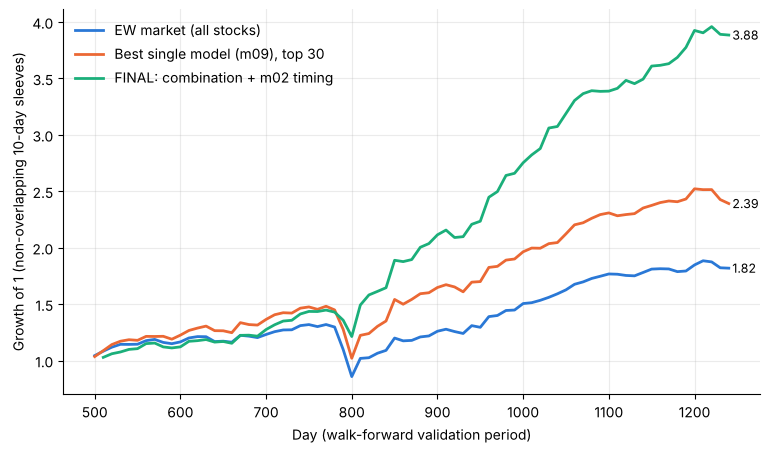

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"EW market (all stocks)": "#2a78d6", "Best single model (m09), top 30": "#eb6834", "FINAL: combination + m02 timing": "#1baf7a"}
for k, c in colors.items():
    g = (1 + strategies[k][OOS].iloc[::H]).cumprod()
    ax.plot(g.index, g.values, color=c, lw=2, label=k)
    ax.annotate(f" {g.iloc[-1]:.2f}", (g.index[-1], g.iloc[-1]), fontsize=9, va="center")
ax.set_xlabel("Day (walk-forward validation period)"); ax.set_ylabel("Growth of 1 (non-overlapping 10-day sleeves)")
ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="upper left")
plt.show()

In validation, the final method has more than twice the excess return of the best single model (≈ 1.06% vs ≈ 0.44% per 10 days), with a higher Sharpe ratio (2.47 vs 1.53) and a smaller drawdown. Compared with the version without m12 × m13, the mean return increases from 1.85% to 2.00% per 10 days and the Sharpe ratio from 2.32 to 2.47.

**Caveat:** the decisions about m01 − m07, m12 × m13, N = 30 and the 50% rule were made while looking at this validation period, so these numbers are a little optimistic. Both derived inputs are stable in all four periods of dev (t ≈ 12–13), so I expect the main effects to hold in test. The exact return will be lower.

## 9. Final fit on all dev data → submission

The test period has no prices, so the model cannot learn during the test. All weights are fitted once on all of dev and then applied to every test day.

In [21]:
N_TOP, LOW_INVEST = 30, 0.5

# 1) input weights: IC-weighted with the winsorized IC, only |t| > 2
ic_all = pd.DataFrame({m: winsor_ic(F[m], Y) for m in FEATS}).loc[:LAST]
s = ic_all.iloc[::H]; t_all = s.mean() / s.std() * np.sqrt(len(s)); mu_all = ic_all.mean()
w_final = pd.Series(np.where(t_all.abs() > 2, mu_all, 0.0), index=FEATS); w_final /= w_final.abs().sum()
display(pd.DataFrame({"IC": mu_all, "t": t_all, "weight": w_final}).round(4))

# 2) timing model on all dev
Z = pd.concat([m02_mean, mkt], axis=1).loc[:LAST].dropna().iloc[::H]
tm = sm.OLS(Z.iloc[:, 1], sm.add_constant(Z.iloc[:, 0])).fit()
print("timing model: market10d = %.5f + %.4f * mean(m02)   (t of slope = %.2f)" % (tm.params.iloc[0], tm.params.iloc[1], tm.tvalues.iloc[1]))

# 3) apply to test
FT = {m: wide(test, m) for m in MODELS}; FT["d01_07"] = FT["m01"] - FT["m07"]
FT["x12_13"] = winsorize_z(FT["m12"]) * winsorize_z(FT["m13"])
score_test = sum(w_final[m] * grank(FT[m]).fillna(0) for m in FEATS if w_final[m] != 0).where(FT["m03"].notna())
invest_test = pd.Series(np.where(tm.params.iloc[0] + tm.params.iloc[1] * FT["m02"].mean(axis=1) >= 0, 1.0, LOW_INVEST),
                        index=score_test.index)
W_test = portfolio(score_test, N_TOP, "score").mul(invest_test, axis=0)

sub = W_test.stack().rename("weight").reset_index(); sub.columns = ["day", "stock", "weight"]
sub = sub[sub.weight > 0].sort_values(["day", "weight"], ascending=[True, False])
sub["weight"] = sub.weight.round(6)
over = sub.groupby("day").weight.transform("sum") > 1
sub.loc[over, "weight"] = (sub.loc[over, "weight"] - 1e-6).clip(lower=0)
with open("submission_Fedja_Bogataj.csv", "w") as fh:
    fh.write("day,stock,weight\n"); sub.to_csv(fh, index=False, header=False, float_format="%.6f")
print(f"written: {len(sub)} rows, {sub.day.nunique()} days, share of days at 50% invested: {(invest_test < 1).mean():.1%}")

,IC,t,weight
m02,0.0037,1.2413,0.0000
m03,0.0226,5.0382,0.0974
m04,0.0107,2.7902,0.0461
m05,0.0091,0.7173,0.0000
m06,-0.0038,-0.0716,0.0000
m08,0.0189,2.0869,0.0812
m09,0.0351,8.8817,0.1512
m10,-0.0203,-4.6479,-0.0874
m11,-0.0043,-0.9531,0.0000
m12,0.0007,0.4914,0.0000


timing model: market10d = 0.00652 + 0.8815 * mean(m02)   (t of slope = 3.26)


written: 35160 rows, 1172 days, share of days at 50% invested: 21.9%


**Check the submission against the rules:**

In [22]:
chk = pd.read_csv("submission_Fedja_Bogataj.csv")
valid = set(zip(test.day, test.stock)); daily = chk.groupby("day").weight.sum()
print("columns OK:            ", list(chk.columns) == ["day", "stock", "weight"])
print("all (day, stock) valid:", all(x in valid for x in zip(chk.day, chk.stock)))
print("all weights >= 0:      ", (chk.weight >= 0).all())
print("max daily sum <= 1:    ", daily.max() <= 1, f"({daily.min():.4f} – {daily.max():.6f})")
print("all test days covered: ", chk.day.nunique() == test.day.nunique())
print("distribution check (std dev vs test):", {m: (round(dev[m].std(), 4), round(test[m].std(), 4)) for m in ["m01", "m07", "m09", "m02", "m12", "m13"]},
      "| corr(m01, m07) dev/test:", round(dev[["m01", "m07"]].corr().iloc[0, 1], 3), round(test[["m01", "m07"]].corr().iloc[0, 1], 3),
      "| corr(m12, m13) dev/test:", round(dev[["m12", "m13"]].corr().iloc[0, 1], 3), round(test[["m12", "m13"]].corr().iloc[0, 1], 3))

columns OK:             True
all (day, stock) valid: True
all weights >= 0:       True
max daily sum <= 1:     True (0.5000 – 1.000000)
all test days covered:  True
distribution check (std dev vs test): {'m01': (np.float64(0.0797), np.float64(0.0806)), 'm07': (np.float64(0.0813), np.float64(0.0822)), 'm09': (np.float64(0.4795), np.float64(0.4438)), 'm02': (np.float64(0.0229), np.float64(0.0229)), 'm12': (np.float64(0.02), np.float64(0.02)), 'm13': (np.float64(0.0224), np.float64(0.0224))} | corr(m01, m07) dev/test: 0.98 0.981 | corr(m12, m13) dev/test: -0.001 -0.0


## 10. Conclusions

### What I can say about the individual models

| Model(s) | Finding | Use |
|---|---|---|
| **m01, m07** | Near-copies (corr 0.98). Each alone ≈ no signal, because both contain a large common noise term. **Their difference is a strong signal** (IC 0.054, t ≈ 12, stable). | as `m01 − m07`, ≈ 25% weight |
| **m12 × m13** | m12 alone ≈ no signal, but its skill **flips sign with m13**: IC ≈ +0.06 where m13 is high, −0.06 where it is low. **Their product is a strong signal** (IC 0.057, t ≈ 13, stable). Found with GBM permutation importance. | as `m12 × m13`, ≈ 25% weight |
| **m09** | Best single original model by ranks (t ≈ 9.7), but values have extreme outliers (±65) and a wrong scale. Signal somewhat weaker in the last period. | ranks only, 3rd largest weight |
| **m03, m08** | Small, positive, stable ranking signals. m08 also has a positive bias (mean +0.4%). | positive weight |
| **m04** | Small positive signal. Below the threshold with the rank IC (t ≈ 1.9), clearly above it with the winsorized IC (t ≈ 2.8): its forecast **sizes** carry information. | positive weight |
| **m10** | **Reliably wrong** in all four periods (t ≈ −4.5). | negative weight |
| **m13** | Alone weakly wrong (t ≈ −2.3); mainly useful together with m12. | small negative weight + in the product |
| **m02** | No ranking skill, but its average forecast predicts the **market direction** (stable in all thirds). | cash decision |
| **m05, m06** | Slow-moving; their size is linked to future **volatility**, not direction. m06 changes sign over time. | not used |
| **m11** | Worked at the start, then turned negative (decay / regime change). | not used |
| **m14, m15** | Noise. m14 also has a negative bias. | not used |

### Why this solution
1. **Understand before combining.** Most of the gain does not come from a clever combiner, but from three observations: fix the signs (m10, m13), remove noise and unstable models, and find the two hidden effects (m01 − m07 and m12 × m13). GBM was useful as a **tool to find** these effects, not as the final combiner.
2. **Simple, robust combiner.** IC-weighted average of Gaussian ranks: one weight per input, stable over time, as good as ridge regression and better than gradient boosting once the two derived inputs are included.
3. **Honest validation.** Walk-forward with a purge, non-overlapping t-stats, and robustness checks before trusting a result (the cash rule).
4. **Respect the rules.** Long-only, top 30 stocks score-weighted, 50–100% invested.
5. **Judge with sizes, combine with ranks.** The winsorized IC (uses forecast sizes, limits outliers) is better for selecting and weighting the inputs; Gaussian ranks are better for combining them (section 5.1).

### Limits and what I would do next
- Validation choices (m01 − m07, m12 × m13, the IC form, N, weights, cash rule) were made on the same period → results are a little optimistic. Each change is small and has a reason, but together they add some selection bias.
- Score weights concentrate the portfolio: the 5 largest positions hold ≈ 42% of the invested capital on average, the largest one ≈ 11% (max ≈ 26%). A weight cap (e.g. 10%) would reduce single-stock risk; I did not add it, because it is an untested change.
- The cash rule relies on a modest effect (corr ≈ 0.25–0.35); its benefit in validation came mostly from one crash.
- The test period is long (1,172 days) without new outcomes; model skill can decay (m11 and m06 show this can happen).
- I do not know what m12 and m13 measure, so I cannot explain *why* the interaction exists. It is very stable in dev, but an effect without an explanation is more likely to stop working.
- Next steps: risk-aware weighting (use m05/m06 as volatility predictors to scale positions), a volatility-targeted invested fraction, and a check of exposure concentration if sector data were available.